# Step 6 · 时空—语义跨模态对齐与联合状态编码

本 Notebook 严格验证 `E_st`、`E_se`、元数据和图谱节点映射，展示关系约束 Cross-Attention 架构，并输出诚实的单 Case 规则融合基线。由于只有一个语义 Case，不执行不可信的重复样本训练，也不宣称融合性能提升。

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import torch
from IPython.display import display,Markdown
ROOT=next(p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'pyproject.toml').exists())
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from urban_joint_encoder.models.cross_attention import MaskedCrossModalFusion
from urban_joint_encoder.cross_modal_alignment import validate_alignment
from urban_joint_encoder.visualization import make_step6_figures
audit=json.loads((ROOT/'outputs/metrics/fusion_audit.json').read_text(encoding='utf-8'))
alignment=json.loads((ROOT/'outputs/alignment/cross_modal_alignment.json').read_text(encoding='utf-8'))
print('Project root:',ROOT)

Project root: /Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder


## 1. 严格映射验证

映射不依据数组长度猜测，而是联合检查 `E_st_metadata.node_indices`、`E_se_metadata.node_id_to_row_index`、E_se 明确行顺序，以及图谱 `SpatialGrid.node_index` 属性。任一关键检查失败，流水线会直接抛出异常并停止融合。

In [2]:
E_st,E_se,st_meta,se_meta,graph,grid_map,checks=validate_alignment(ROOT)
display(pd.Series(checks,name='passed').to_frame())
assert all(checks.values()) and st_meta['target_row_index']==se_meta['case_row_index']==7347

,passed
E_st_shape_matches_metadata,True
E_se_shape_matches_metadata,True
E_st_case_row_is_7347,True
E_se_case_row_is_7347,True
same_case,True
E_st_node_indices_exact,True
E_se_row_mapping_bijective,True
E_se_node_order_exact,True
graph_node_set_matches_E_se,True
graph_has_exact_grid_indices,True


## 2. 可追溯关系约束 Mask

每个空间网格只允许关注：自身语义网格、HAS_POI 类别、OCCURS_AT 事件、一跳相邻网格，以及通过事件关系到达的演示规则。每个允许项的完整语义路径记录在 alignment JSON 中。

In [3]:
mask=np.load(ROOT/'outputs/alignment/attention_mask.npy')
display(pd.Series(audit['attention_mask'],name='attention_mask').to_frame())
print('mask dtype:',mask.dtype,'shape:',mask.shape,'all rows covered:',mask.any(axis=1).all())
assert mask.shape==(265,277) and mask.any(axis=1).all()

,attention_mask
shape,"[265, 277]"
valid_element_count,2314
total_element_count,73405
coverage_ratio,0.031524
valid_keys_per_query,"{'minimum': 2, 'maximum': 13, 'mean': 8.732075..."


mask dtype: bool shape: (265, 277) all rows covered: True


## 3. Cross-Attention 架构与实际 Forward

模型包含 4-head MultiheadAttention、可学习门控残差和 LayerNorm。下列权重来自实际 PyTorch forward，但模型参数没有训练，因此只能视为架构演示中的权重分配，不能解释为学到的关系或因果贡献。

In [4]:
demo=np.load(ROOT/'outputs/alignment/untrained_attention_forward.npz')
model_info=audit['cross_attention_architecture']
display(pd.Series(model_info,name='cross_attention').to_frame())
print({k:demo[k].shape for k in demo.files})
assert demo['attention_weights'].shape==(4,265,277) and model_info['forward_executed'] and not model_info['trained']

,cross_attention
embedding_dim,32
num_heads,4
parameter_count,6368
trained,False
forward_executed,True
attention_weights_shape,"[4, 265, 277]"
attention_weights_source,Actual PyTorch MultiheadAttention forward with...


{'semantic_context': (265, 32), 'joint': (265, 32), 'attention_weights': (4, 265, 277), 'gate': (265, 32)}


## 4. E_joint：确定性规则融合基线

没有把单个 Case 重复为训练数据。`E_joint` 使用可审计关系类别权重形成语义上下文，再计算 `LayerNorm(0.75×LayerNorm(E_st) + 0.25×LayerNorm(context))`。它是规则基线，不是训练后的 Cross-Attention 表示。

In [5]:
E_joint=np.load(ROOT/'outputs/embeddings/E_joint.npy')
joint_meta=json.loads((ROOT/'outputs/embeddings/E_joint_metadata.json').read_text(encoding='utf-8'))
print('E_joint:',E_joint.shape,E_joint.dtype)
display(pd.Series({k:v for k,v in joint_meta.items() if k not in ('query_node_indices','rule_category_weights_before_per_query_normalization')},name='E_joint').to_frame())
display(pd.DataFrame(audit['grid_146_rule_weights']))
assert E_joint.shape==(265,32) and not joint_meta['trained']

E_joint: (265, 32) float32


,E_joint
shape,"[265, 32]"
dtype,float32
case_row_index,7347
method,deterministic traceable rule-weighted baseline
trained,False
fixed_semantic_gate,0.25
formula,LayerNorm(0.75*LayerNorm(E_st) + 0.25*LayerNor...
alignment,outputs/alignment/cross_modal_alignment.json
warning,"This is a single-case rule fusion baseline, no..."


,semantic_node_id,semantic_row_index,normalized_weight,categories
0,grid:146,146,0.340909,[SELF_SPATIAL_GRID]
1,poi_category:0,265,0.151515,[HAS_POI]
2,poi_category:6,271,0.151515,[HAS_POI]
3,grid:144,144,0.075758,[ONE_HOP_ADJACENT_GRID]
4,grid:147,147,0.075758,[ONE_HOP_ADJACENT_GRID]
5,event:grid_146:rows_7345_7349,272,0.151515,[LOCAL_EVENT]
6,event:grid_147:rows_7347_7348,273,0.022727,[EVENT_RELATION]
7,rule:monitor_adjacent,275,0.015152,[EVENT_PATH_RULE]
8,rule:review_poi_context,276,0.015152,[EVENT_PATH_RULE]


## 5. Figure 17–22

Figure 17 是架构示意；Figure 18–19 来自实际映射；Figure 20 来自实际但未训练的 forward，并显著标注；Figure 21–22 展示确定性规则融合结果，不声称性能改善。

findfont: Failed to find font weight bold for PingFang SC, now using 600.


findfont: Failed to find font weight bold for PingFang SC, now using 600.


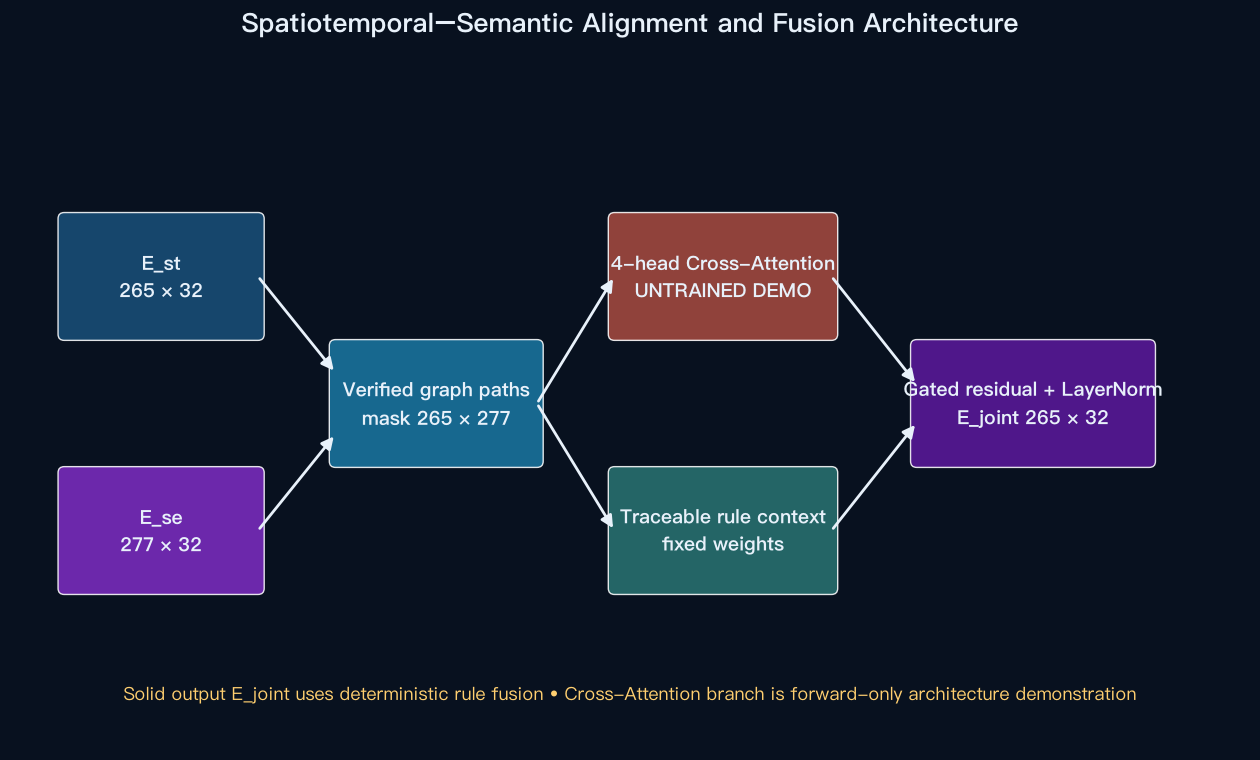

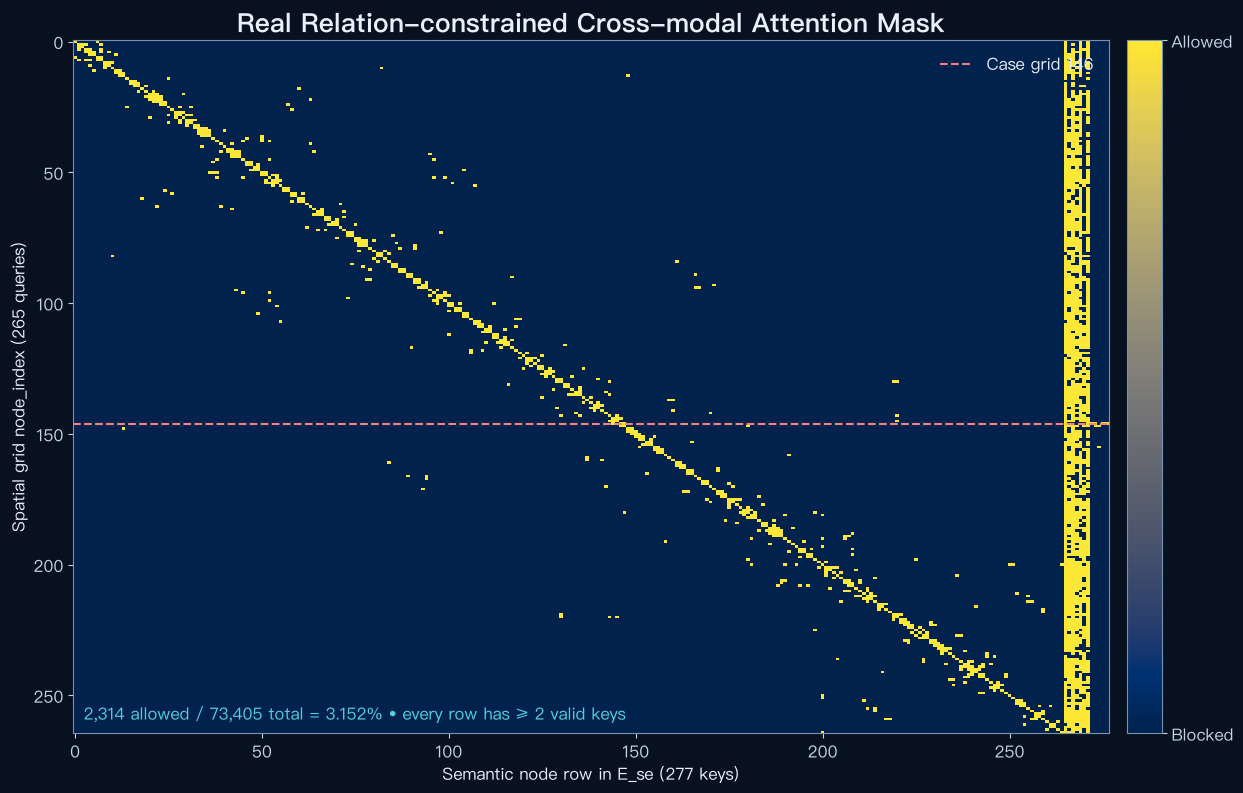

findfont: Failed to find font weight bold for PingFang SC, now using 600.


findfont: Failed to find font weight bold for PingFang SC, now using 600.


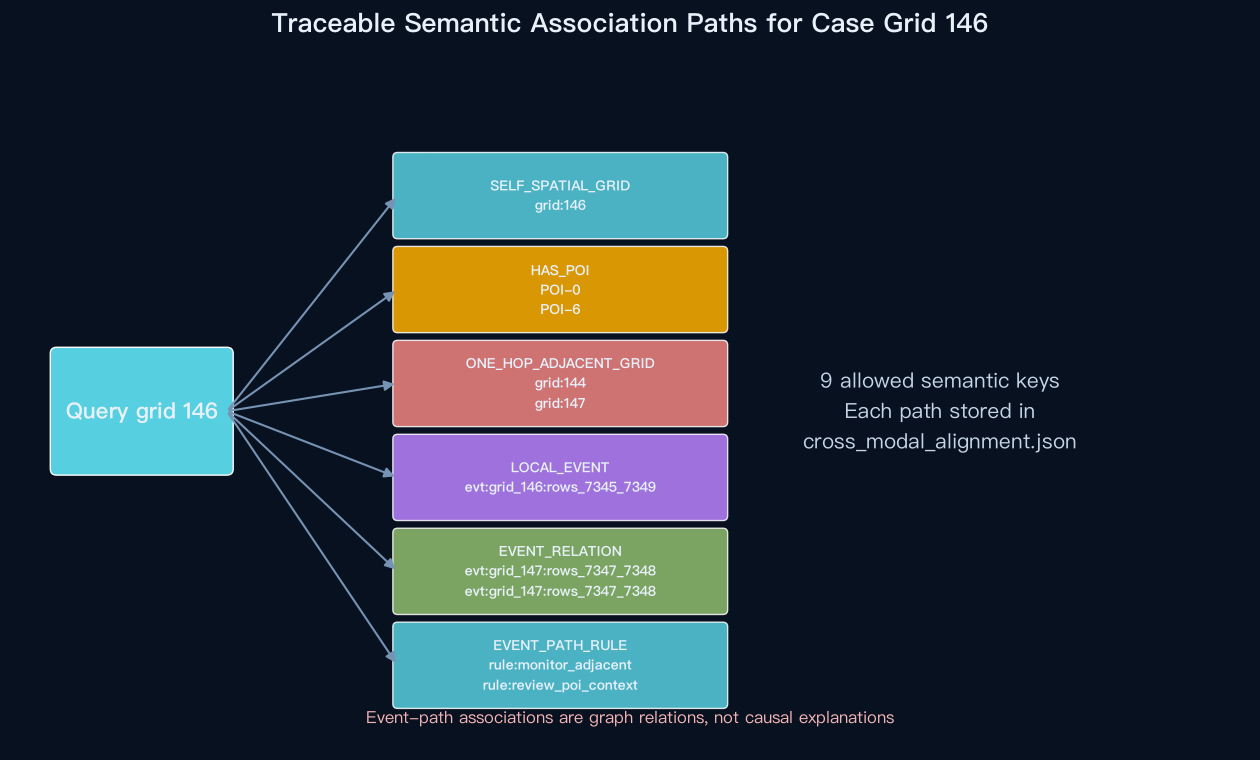

findfont: Failed to find font weight bold for PingFang SC, now using 600.


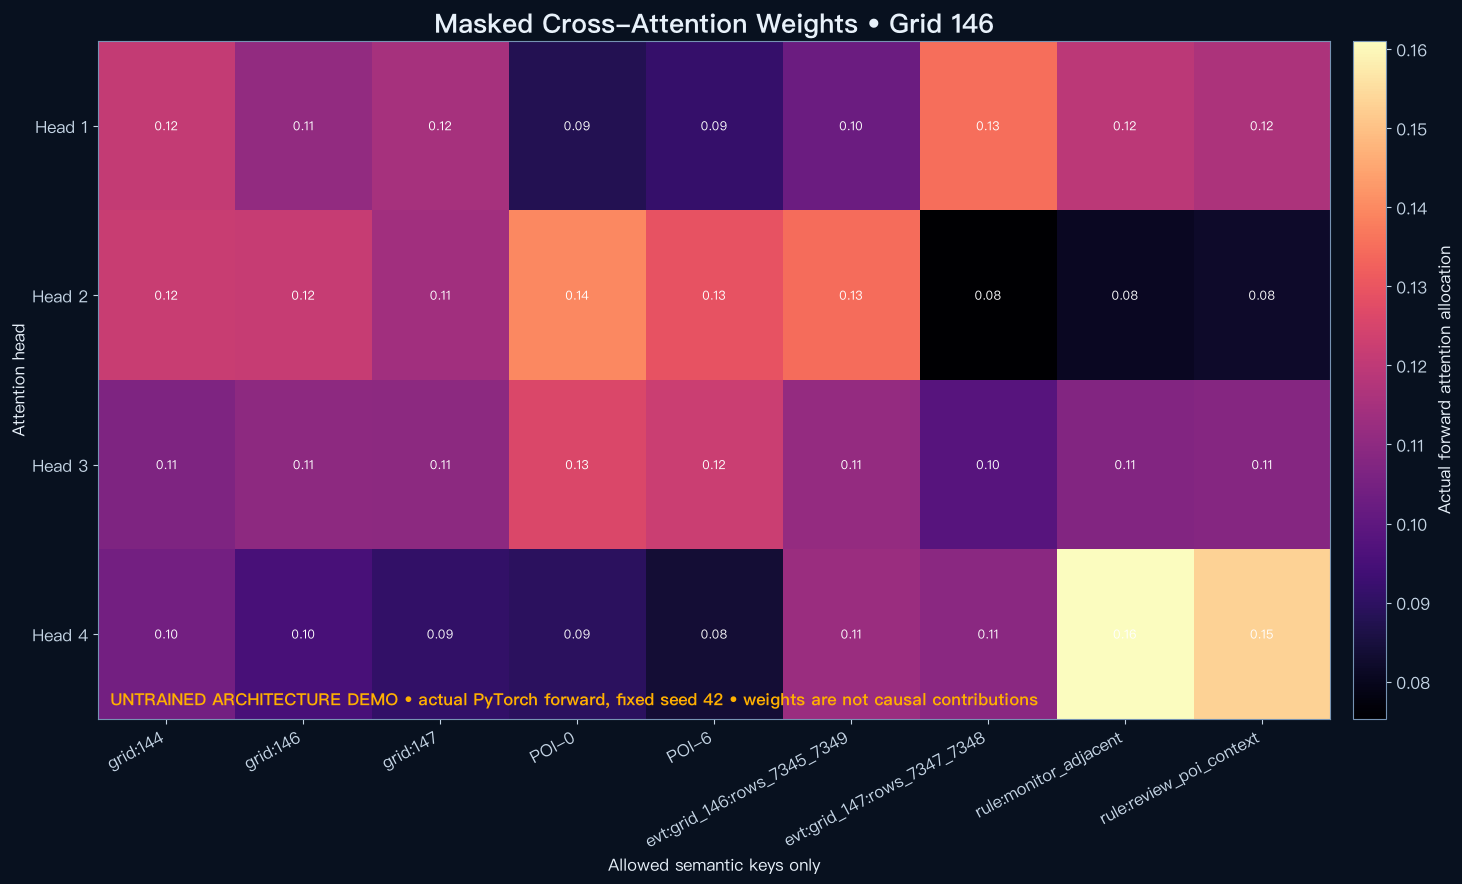

findfont: Failed to find font weight bold for PingFang SC, now using 600.


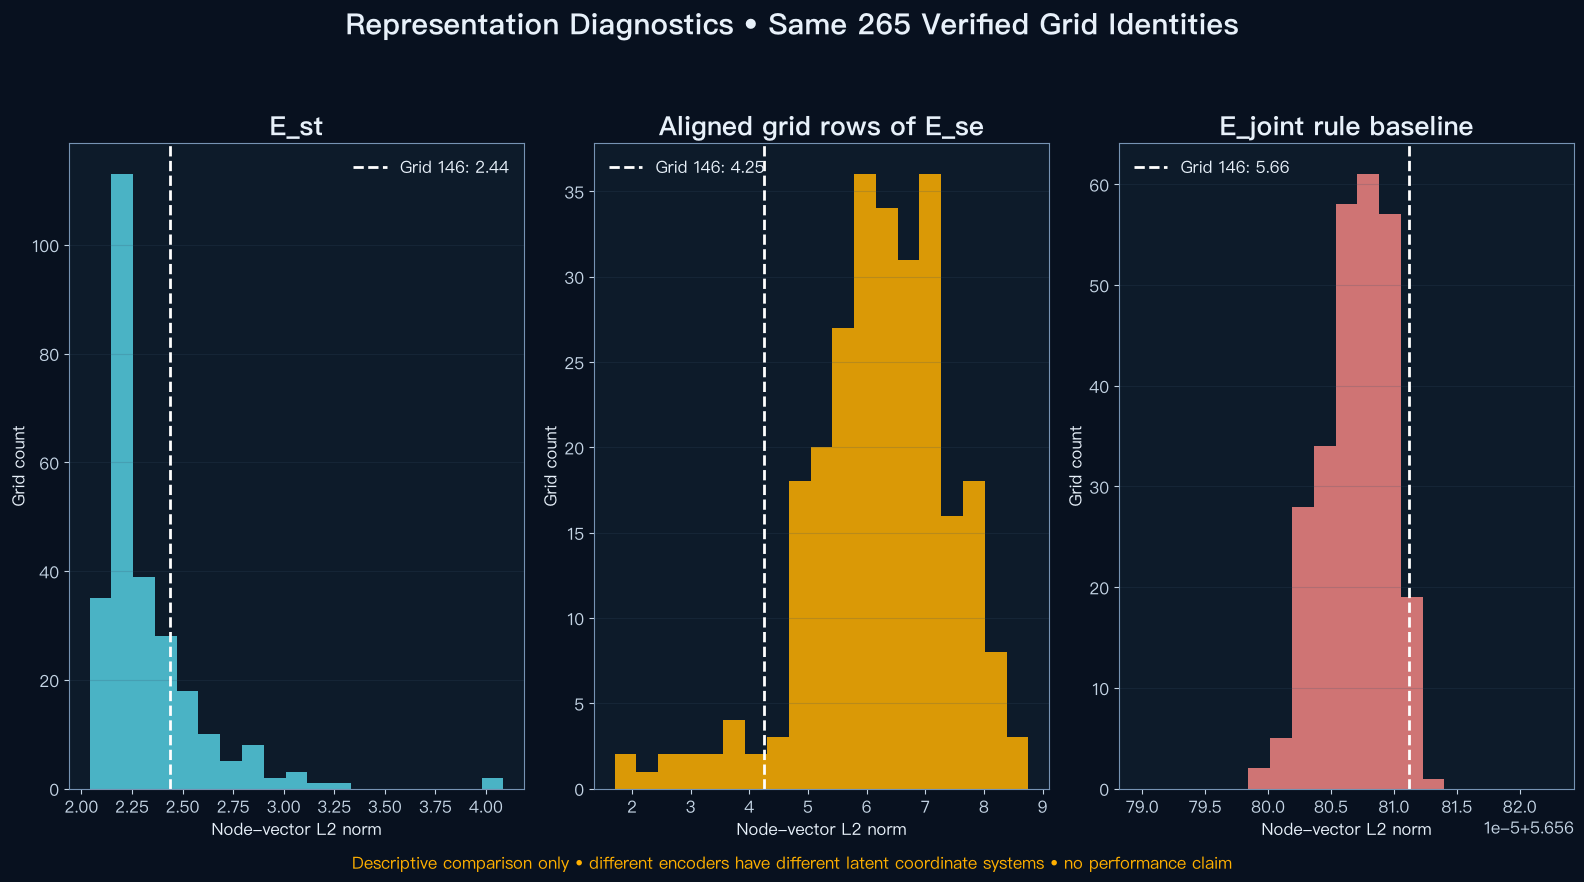

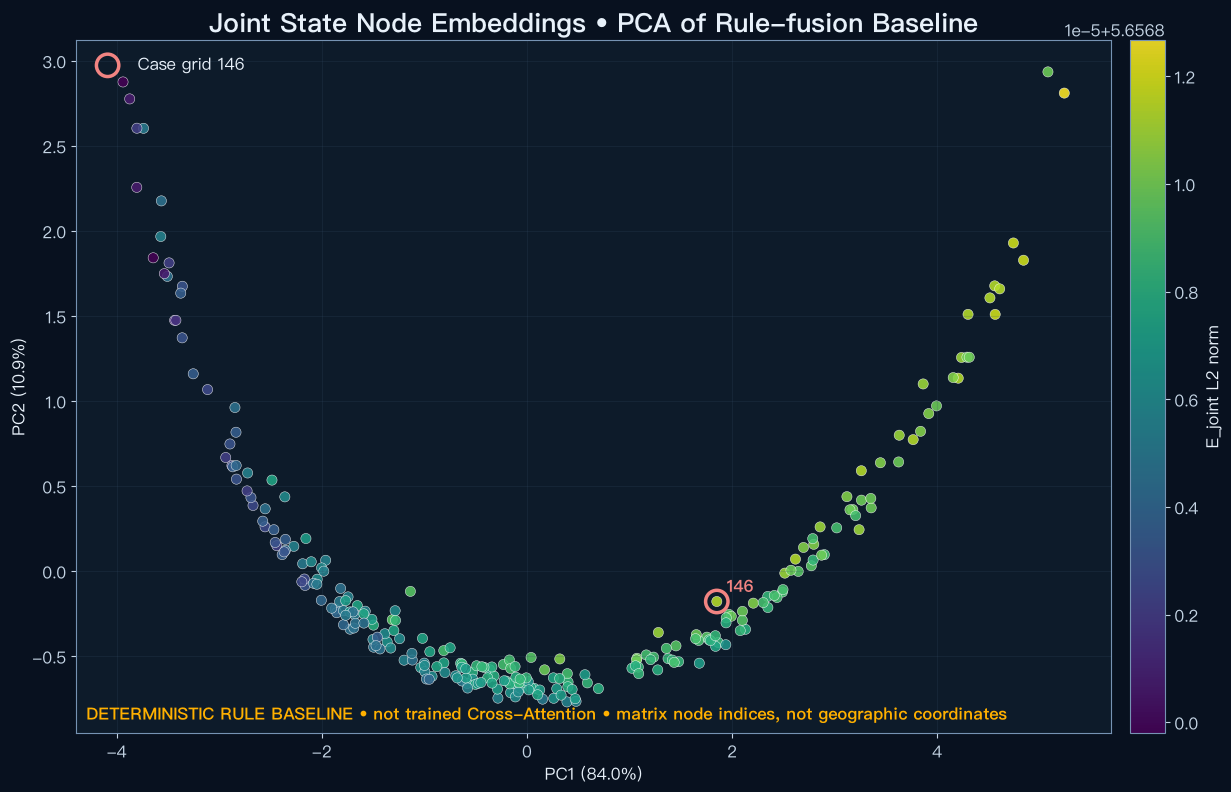

,PNG,SVG
figure_17,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_18,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_19,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_20,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_21,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_22,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...


In [6]:
figure_outputs=make_step6_figures(ROOT)
display(pd.DataFrame({k:v for k,v in figure_outputs.items()},index=['PNG','SVG']).T)

## 6. 数据泄漏与后续条件

本阶段没有融合训练样本、没有未来监督、没有重复单 Case，Step 4/5 编码器也未重训。下一阶段若要开展可信的联合预测和消融实验，必须先为多个独立时间窗口构建因果语义快照，并按时间划分训练/验证/测试；当前产物适合接口验证、Case 展示和规则基线，不足以证明学习式融合有效。